# 04. Variant B: rolling one-step forecasting

In variant B each forecast is one step ahead, and the actual value arrives right after. The parameters stay frozen:

1. forecast `t+1` using only what was observed up to `t`;
2. observe `y[t+1]`;
3. update the residual window with the base's error at that moment;
4. move forward, **without calling `fit`**.

Selection uses the one-step error on validation. Dynamic corrector selection is allowed only in this variant.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Experiment in variant B

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")
exp = AutoHybridExperiment(fh=1, variant="B", test_size=28, session_id=42).fit(y)
result = exp.compare_models()
result.leaderboard

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
f197a4a852eefc42b77e9d063dff3c84cf252feda2deb62c878faf84713a4449,arima,arima,statistical,standalone,arima,NaN,NaN,NaN,NaN,1.0,...,0.883120,0.883120,0.012429,1.0,7,0,0,15.198200,0.016822,True
dcc94aa07bedae7630b1f38c2570937852793c439f560bfd9098cbedf9650690,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,0.5,2.0,...,0.885318,0.885318,0.012459,1.0,7,0,0,5.176990,0.013707,False
0ec158f3b6ec517f088da25b7c2f75c10bfe627d7bf5437f0622b8ff36cca85a,arima-linear,"arima + linear [w=7, alpha=0.5, in_sample]",residual,residual_additive,arima,linear,in_sample,7.0,0.5,3.0,...,0.886370,0.886370,0.012471,1.0,7,0,0,0.294483,0.017429,False
50c3b10b84c20c32b6b898008596592cb4f651f3f73110b54230461381267f3e,arima-linear,"arima + linear [w=7, alpha=1.0, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,1.0,4.0,...,0.891898,0.891898,0.012552,1.0,7,0,0,0.382575,0.013364,False
c51a658f4db43de6316044da15702a7d11e9e319df05363c4688b9ba00547929,mlp,mlp(lags=7),neural,standalone,mlp,NaN,NaN,NaN,NaN,5.0,...,0.892754,0.892754,0.012454,1.0,7,0,0,0.709854,0.001972,False
4a92d125bd10f30ce4cdf0fc07e114c1e0d07bbd03ca06dd5a8c04c2781bfd4b,svm,svm(lags=7),kernel,standalone,svm,NaN,NaN,NaN,NaN,6.0,...,0.926790,0.926790,0.013126,1.0,7,0,0,0.102796,0.003013,False
c05fbfc4191206898692474cb6edb6c95948dcd38fd203e4d6be47b604035efe,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,7.0,...,0.939771,0.939771,0.013160,1.0,7,0,0,1.121752,0.001502,False
3e1cf077f43789200b40b04ab5b6098eb7f916132b72ca9bbd6f6f8eba5f3d02,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_multistep,7.0,0.5,8.0,...,0.958163,0.958163,0.013517,1.0,7,0,0,10.260249,0.012560,False
1984f459ddd73973f8dee0312933d0c5d4a4ae9ff5e3e8a400a30bd0b87baff5,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,9.0,...,1.002286,1.002286,0.013990,1.0,7,0,0,0.503549,0.002599,False


## 2. Finalize and evaluate on the sealed test

In [3]:
final = exp.finalize_model(result.best)
exp.evaluate_external(final).metrics

,MASE,MAE,RMSE,sMAPE
model,,,,
arima,0.532694,0.83562,1.022446,0.011846


## 3. Streaming in production

The same model, receiving new observations one by one. Here we simulate the arrival of the data with the last 28 observations of the series.

In [4]:
import pandas as pd

stream = final.stream()
rows = []
for timestamp, actual in y.iloc[-28:].items():
    ticket = stream.predict_next()
    rows.append({"timestamp": timestamp, "y_pred": ticket.prediction, "y_true": actual})
    stream.observe(actual)  # only now does the actual value become available

stream_log = pd.DataFrame(rows).set_index("timestamp")
stream_log["abs_error"] = (stream_log["y_true"] - stream_log["y_pred"]).abs()
stream_log

,y_pred,y_true,abs_error
timestamp,,,
2025-12-03,73.163889,72.429605,0.734284
2025-12-04,70.867025,71.246072,0.379047
2025-12-05,68.793807,70.065617,1.271810
2025-12-06,68.582059,67.422345,1.159713
2025-12-07,68.022263,67.361921,0.660342
2025-12-08,69.636127,70.737740,1.101613
2025-12-09,73.005390,73.033376,0.027986
2025-12-10,73.587046,74.455786,0.868740
2025-12-11,72.897800,72.770706,0.127095


## 4. Forecast × observed

Each orange point was forecast before the black value was observed; the model only saw the past of each point.

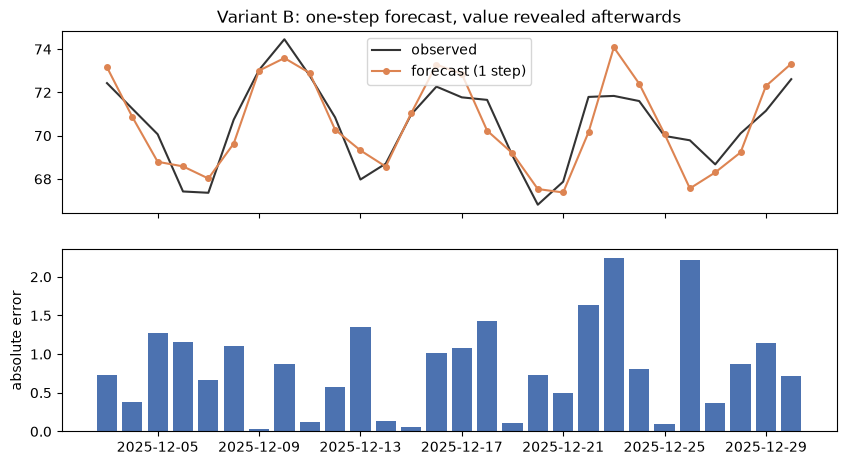

In [5]:
import matplotlib.pyplot as plt

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(stream_log.index, stream_log["y_true"], color="#333333", label="observed")
top.plot(
    stream_log.index,
    stream_log["y_pred"],
    "o-",
    color="#DD8452",
    markersize=4,
    label="forecast (1 step)",
)
top.set_title("Variant B: one-step forecast, value revealed afterwards")
top.legend()
bottom.bar(stream_log.index, stream_log["abs_error"], color="#4C72B0")
bottom.set_ylabel("absolute error")
plt.show()

## 5. Base and correction at each step

The champion here is a standalone model, without a corrector. To see what variant B does in a hybrid, `arima-linear` is evaluated on the same origins, finalized and streamed over the same 28 days. Each `ForecastTicket` carries the base forecast and the correction; the observed residual `y − b` enters the corrector window only after the observation.

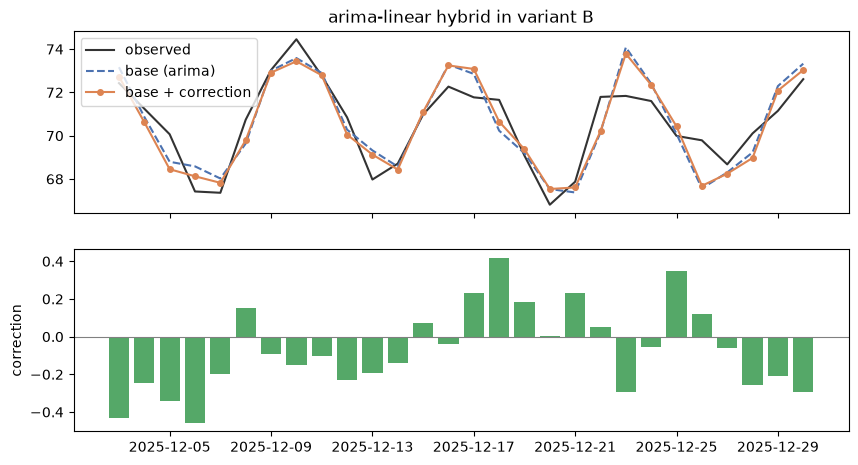

base                 0.836
base + correction    0.803
Name: MAE over the 28 days, dtype: float64

In [6]:
hybrid = exp.create_hybrid("arima", "linear")
hybrid_stream = exp.finalize_model(hybrid).stream()
steps = []
for timestamp, actual in y.iloc[-28:].items():
    ticket = hybrid_stream.predict_next()
    steps.append(
        {
            "timestamp": timestamp,
            "base": ticket.base_prediction,
            "correction": ticket.correction,
            "y_pred": ticket.prediction,
            "y_true": actual,
        }
    )
    hybrid_stream.observe(actual)
steps = pd.DataFrame(steps).set_index("timestamp")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(steps.index, steps["y_true"], color="#333333", label="observed")
top.plot(steps.index, steps["base"], "--", color="#4C72B0", label="base (arima)")
top.plot(
    steps.index, steps["y_pred"], "o-", color="#DD8452", markersize=4, label="base + correction"
)
top.set_title("arima-linear hybrid in variant B")
top.legend()
bottom.bar(steps.index, steps["correction"], color="#55A868")
bottom.axhline(0, color="gray", linewidth=0.8)
bottom.set_ylabel("correction")
plt.show()
errors = {
    "base": (steps["y_true"] - steps["base"]).abs().mean(),
    "base + correction": (steps["y_true"] - steps["y_pred"]).abs().mean(),
}
pd.Series(errors, name="MAE over the 28 days").round(3)

## 6. Variants A and B on the same stretch

The same champion structure, now in variant A: finalized on the same history, it forecasts the 28 days at once from the end of training, without seeing any value of that stretch. In variant B, each day was forecast with the previous days already observed. This is the difference described on the "Variants A and B" page of the user guide.

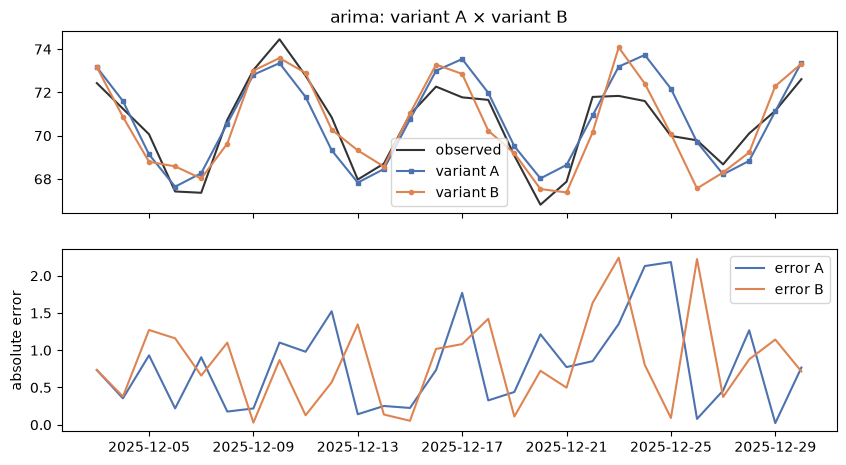

A (28 steps)    0.791
B (1 step)      0.836
Name: MAE, dtype: float64

In [7]:
from dataclasses import replace

exp_a = AutoHybridExperiment(fh=28, test_size=28, session_id=42).fit(y)
final_a = exp_a.finalize_model(replace(result.best, variant="A"))  # same structure, variant A
forecast_a = exp_a.predict_model(final_a).predictions["y_pred"]

comparison = pd.DataFrame(
    {
        "y_true": stream_log["y_true"],
        "A (28 steps)": forecast_a.to_numpy(),
        "B (1 step)": stream_log["y_pred"],
    }
)
error_a = (comparison["y_true"] - comparison["A (28 steps)"]).abs()
error_b = (comparison["y_true"] - comparison["B (1 step)"]).abs()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(comparison.index, comparison["y_true"], color="#333333", label="observed")
top.plot(
    comparison.index,
    comparison["A (28 steps)"],
    "s-",
    color="#4C72B0",
    markersize=3,
    label="variant A",
)
top.plot(
    comparison.index,
    comparison["B (1 step)"],
    "o-",
    color="#DD8452",
    markersize=3,
    label="variant B",
)
top.set_title(f"{result.best.label}: variant A × variant B")
top.legend()
bottom.plot(comparison.index, error_a, color="#4C72B0", label="error A")
bottom.plot(comparison.index, error_b, color="#DD8452", label="error B")
bottom.set_ylabel("absolute error")
bottom.legend()
plt.show()
pd.Series({"A (28 steps)": error_a.mean(), "B (1 step)": error_b.mean()}, name="MAE").round(3)

## 7. Reading

* **Streaming.** The champion (`arima`) forecast the 28 days one step at a time, without refitting, with MAE 0.836 — the same value as the external evaluation, which in variant B is also a one-step rolling forecast.
* **Base and correction.** In the `arima-linear` hybrid, the correction stayed below 0.5 in absolute value on every day and lowered the 28-day MAE from 0.836 (base alone) to 0.803; each correction used only residuals already observed.
* **A × B.** On this stretch variant A had the lower MAE (0.791 against 0.836). The chosen `arima` projects the weekly cycle and the trend well 28 days ahead, and A's error did not grow with the horizon; the one-step forecast reacts to the latest value, which carries the AR(1) noise. Variant B does not guarantee a lower error: it is meant for when each value arrives before the next forecast. On series with a less predictable component, A's error tends to grow with the horizon.
* **Limits.** A single 28-day stretch of a synthetic series; the comparison illustrates the mechanics, it does not estimate which variant errs less in general.